# 01 · Análisis exploratorio de datos (EDA)

**Predicción del riesgo de sanción de proveedores en las contrataciones públicas peruanas** · Inteligencia Artificial Aplicada (1INF62) · 2026-2

En este notebook exploramos el dataset final que construimos en `00_preprocesamiento.ipynb` (`data/processed/dataset_proveedor_corte.csv`). Antes de entrenar cualquier modelo queríamos entender qué hay realmente en los datos: cómo quedó construida la variable objetivo, qué tan desbalanceada es, dónde faltan valores y por qué, cómo se distribuyen las variables, qué valores atípicos existen y qué señales iniciales aparecen frente a una sanción futura.

Este notebook **solo describe y diagnostica**: no modifica los datos ni guarda archivos. Las decisiones de preparación para los modelos (imputación, escalado, tratamiento de valores atípicos y balanceo) se justifican en la sección final y se aplicarán en `02_modelos.ipynb`, ajustadas únicamente con el conjunto de entrenamiento para no filtrar información del futuro.

**Contenido**

| Sección | Tema |
|---|---|
| 0 | Contexto: qué representa cada fila y cómo se construyó |
| 1 | Carga de datos |
| 2 | Vista general y grupos de variables |
| 3 | Estructura: cortes y proveedores |
| 4 | Variable objetivo y desbalance de clases |
| 5 | Columnas de control |
| 6 | Valores faltantes |
| 7 | Escalas de las variables |
| 8 | Distribuciones |
| 9 | Calidad de datos y valores atípicos |
| 10 | Relación de las variables con el target |
| 11 | Evolución entre cortes |
| 12 | Conclusiones y decisiones para el modelado |

## 0. Contexto: qué representa cada fila

**Pregunta que guía el proyecto.** ¿Es posible estimar, usando solo información disponible hasta una fecha de corte, qué proveedores del Estado peruano tienen mayor riesgo de recibir una sanción (inhabilitación o multa) durante los 12 meses siguientes? El resultado se plantea como una herramienta para **priorizar revisiones**; no pretende demostrar culpabilidad, fraude ni corrupción.

**Unidad de análisis.** Cada fila es un **proveedor en una fecha de corte** `t`. Las variables describen su historial de contratación *hasta* `t`, y el target indica si el proveedor recibió una sanción con fecha entre `t` y `t + 12 meses`. Así, la información futura se usa únicamente para construir la etiqueta y nunca como predictora.

**Fuentes.** Trabajamos con datos abiertos del OECE/SEACE: contratos y convocatorias (archivos anuales 2023–2026), entidades contratantes y sanciones (RNP del Tribunal de Contrataciones y listas de CONOSCE, con inhabilitaciones y multas).

**Decisiones de construcción que conviene tener presentes al leer este análisis**

- **Cruce de fuentes.** Unimos cada contrato-ítem con su convocatoria (por código de convocatoria e ítem) y con su entidad (por código de entidad sin ceros iniciales). Después agregamos a una fila por contrato.
- **Sin información posterior a la firma.** Descartamos montos adicionales, reducciones, prórrogas, complementarios, vigencia actualizada y resolución del contrato, porque reflejan lo que pasó *después* de firmar y habrían filtrado información del futuro.
- **Disponibilidad del contrato.** Un contrato cuenta en un corte solo si ya estaba firmado y publicado en esa fecha.
- **Identificador del proveedor.** Cuando el contratista figura con un código numérico de 6 a 8 dígitos (consorcio probable), usamos el RUC del destinatario de pago. Los proveedores extranjeros, que no tienen RUC y no pueden aparecer en las listas de sancionados, se excluyeron porque su etiqueta no es observable.
- **Sanciones.** Unimos las cuatro tablas (RNP y CONOSCE, inhabilitaciones y multas) sin repetir una misma resolución. La fecha del evento es el inicio de la inhabilitación o la fecha de resolución de la multa.
- **Cortes.** Usamos cuatro cortes: 31/12/2023, 30/06/2024, 31/12/2024 y 30/06/2025. Son los que tienen historial de contratos y una ventana de 12 meses completa dentro de la fecha de las bases de sanciones.
- **Montos solo en soles.** No convertimos monedas: los contratos en otra moneda cuentan como actividad pero no suman monto.
- **Nulos sin imputar.** Dejamos los valores faltantes tal cual para decidir su tratamiento con criterio durante el modelado (ver sección 6).

## 1. Carga de datos

Leemos el archivo procesado desde `data/processed/` a partir de la raíz del repositorio. El RUC se carga como texto para conservar los 11 dígitos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

COLOR_0, COLOR_1 = "#4ECDC4", "#FF6B6B"


def localizar_raiz_repo():
    cwd = Path.cwd().resolve()
    for carpeta in [cwd, *cwd.parents]:
        if (carpeta / "data" / "processed").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró data/processed. Ejecutar primero 00_preprocesamiento.ipynb desde el repositorio.")


ROOT = localizar_raiz_repo()
ruta_csv = ROOT / "data" / "processed" / "dataset_proveedor_corte.csv"
ruta_xlsx = ruta_csv.with_suffix(".xlsx")

if ruta_csv.exists():
    df = pd.read_csv(ruta_csv, dtype={"id_proveedor": "string"})
elif ruta_xlsx.exists():
    df = pd.read_excel(ruta_xlsx, sheet_name="dataset", dtype={"id_proveedor": "string"})
else:
    raise FileNotFoundError("No existe el dataset procesado. Ejecutar primero 00_preprocesamiento.ipynb.")

df["fecha_corte"] = pd.to_datetime(df["fecha_corte"])
df["fecha_fin_ventana"] = pd.to_datetime(df["fecha_fin_ventana"])

print("Archivo:", ruta_csv.name if ruta_csv.exists() else ruta_xlsx.name)
print("Filas:", f"{len(df):,}", "| Columnas:", df.shape[1])

Archivo: dataset_proveedor_corte.csv
Filas: 28,731 | Columnas: 53


## 2. Vista general y grupos de variables

El dataset tiene **53 columnas**. Las agrupamos según su rol: identificación, control, target y variables predictoras (organizadas en los grupos de la propuesta: actividad, montos, crecimiento, diversificación, concentración, repetición, frecuencia y antigüedad, composición, proceso y antecedentes). Esta clasificación se usa en el resto del análisis, y la celda verifica que ninguna columna quede sin asignar.

In [2]:
IDENTIFICACION = ["id_proveedor", "fecha_corte"]
CONTROL = ["fecha_fin_ventana", "ventana_etiqueta_completa", "etiqueta_confiable", "meses_cobertura_datos"]
TARGETS = ["target", "y_inhabilitacion_12m", "y_multa_12m"]

GRUPOS = {
    "Actividad": ["n_contratos_hist", "n_contratos_3m", "n_contratos_6m", "n_contratos_12m", "n_contratos_24m"],
    "Montos": ["monto_pen_3m", "monto_pen_6m", "monto_pen_12m", "monto_pen_24m", "monto_pen_hist_total",
               "monto_pen_hist_media", "monto_pen_hist_mediana", "monto_pen_hist_max", "monto_pen_hist_std"],
    "Crecimiento": ["crec_n_6m", "crec_monto_6m", "crec_n_12m", "crec_monto_12m"],
    "Diversificación": ["n_entidades", "n_departamentos", "n_sectores", "n_objetos"],
    "Concentración": ["prop_contratos_entidad_principal", "prop_monto_entidad_principal"],
    "Repetición": ["n_entidades_recurrentes", "prop_contratos_repetidos_entidad"],
    "Frecuencia y antigüedad": ["dias_prom_entre_contratos", "meses_desde_primer_contrato", "meses_desde_ultimo_contrato"],
    "Composición": ["prop_bien", "prop_servicio", "prop_obra", "prop_consultoria_obra",
                    "prop_contratacion_directa", "prop_moneda_extranjera"],
    "Proceso de contratación": ["ratio_contratado_ref_medio", "dias_conv_a_firma_medio", "duracion_contrato_dias_medio"],
    "Antecedentes": ["n_inhab_previas", "n_multas_previas", "tiene_sancion_previa",
                     "dias_desde_ultima_sancion", "inhabilitado_vigente_al_corte"],
    "Tipo de proveedor": ["es_consorcio_probable"],
}
PREDICTORAS = [c for cols in GRUPOS.values() for c in cols]
BINARIAS = ["es_consorcio_probable", "tiene_sancion_previa", "inhabilitado_vigente_al_corte"]
CONTINUAS = [c for c in PREDICTORAS if c not in BINARIAS]

todas = IDENTIFICACION + CONTROL + TARGETS + PREDICTORAS
assert sorted(todas) == sorted(df.columns), set(df.columns) ^ set(todas)

resumen_grupos = pd.DataFrame(
    [("Identificación", len(IDENTIFICACION)), ("Control", len(CONTROL)), ("Target", len(TARGETS))]
    + [(g, len(c)) for g, c in GRUPOS.items()],
    columns=["Grupo", "Columnas"],
)
display(resumen_grupos)
print("Variables predictoras:", len(PREDICTORAS), "| continuas:", len(CONTINUAS), "| binarias:", len(BINARIAS))
df.head()

,Grupo,Columnas
0,Identificación,2
1,Control,4
2,Target,3
3,Actividad,5
4,Montos,9
5,Crecimiento,4
6,Diversificación,4
7,Concentración,2
8,Repetición,2
9,Frecuencia y antigüedad,3


Variables predictoras: 44 | continuas: 41 | binarias: 3


,id_proveedor,fecha_corte,fecha_fin_ventana,ventana_etiqueta_completa,etiqueta_confiable,meses_cobertura_datos,target,y_inhabilitacion_12m,y_multa_12m,es_consorcio_probable,n_contratos_hist,n_contratos_3m,monto_pen_3m,n_contratos_6m,monto_pen_6m,n_contratos_12m,monto_pen_12m,n_contratos_24m,monto_pen_24m,monto_pen_hist_total,monto_pen_hist_media,monto_pen_hist_mediana,monto_pen_hist_max,monto_pen_hist_std,crec_n_6m,crec_monto_6m,crec_n_12m,crec_monto_12m,n_entidades,n_departamentos,n_sectores,n_objetos,prop_contratos_entidad_principal,prop_monto_entidad_principal,n_entidades_recurrentes,prop_contratos_repetidos_entidad,dias_prom_entre_contratos,meses_desde_primer_contrato,meses_desde_ultimo_contrato,prop_bien,prop_servicio,prop_obra,prop_consultoria_obra,prop_contratacion_directa,prop_moneda_extranjera,ratio_contratado_ref_medio,dias_conv_a_firma_medio,duracion_contrato_dias_medio,n_inhab_previas,n_multas_previas,tiene_sancion_previa,dias_desde_ultima_sancion,inhabilitado_vigente_al_corte
0,10000942753,2023-12-31,2024-12-31,1,1,12.0,0,0,0,0,2,0.0,0.0,0.0,0.0,2.0,150375.0,2.0,150375.0,150375.0,75187.5,75187.5,75250.0,88.388348,NaN,NaN,NaN,NaN,1,1,1,1,1.0,1.0,1,0.5,0.0,9.954825,9.954825,0.0,1.0,0.0,0.0,0.0,0.0,0.666857,16.0,88.0,0.0,0.0,0,NaN,0
1,10000990235,2023-12-31,2024-12-31,1,1,12.0,0,0,0,0,2,0.0,0.0,0.0,0.0,2.0,150000.0,2.0,150000.0,150000.0,75000.0,75000.0,75000.0,0.000000,NaN,NaN,NaN,NaN,1,1,1,1,1.0,1.0,1,0.5,0.0,9.954825,9.954825,0.0,1.0,0.0,0.0,0.0,0.0,0.665209,16.0,149.0,0.0,0.0,0,NaN,0
2,10001272077,2023-12-31,2024-12-31,1,1,12.0,0,0,0,0,1,0.0,0.0,0.0,0.0,1.0,60000.0,1.0,60000.0,60000.0,60000.0,60000.0,60000.0,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1.0,1.0,0,0.0,NaN,10.086242,10.086242,0.0,1.0,0.0,0.0,1.0,0.0,1.000000,10.0,730.0,0.0,0.0,0,NaN,0
3,10002167684,2023-12-31,2024-12-31,1,1,12.0,0,0,0,0,1,1.0,112000.0,1.0,112000.0,1.0,112000.0,1.0,112000.0,112000.0,112000.0,112000.0,112000.0,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1.0,1.0,0,0.0,NaN,2.398357,2.398357,0.0,1.0,0.0,0.0,1.0,0.0,1.000000,3.0,365.0,0.0,0.0,0,NaN,0
4,10002223631,2023-12-31,2024-12-31,1,1,12.0,0,0,0,0,1,0.0,0.0,1.0,86856.0,1.0,86856.0,1.0,86856.0,86856.0,86856.0,86856.0,86856.0,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1.0,1.0,0,0.0,NaN,6.143737,6.143737,0.0,1.0,0.0,0.0,0.0,0.0,0.916667,28.0,185.0,0.0,0.0,0,NaN,0


## 3. Estructura: cortes y proveedores

Antes de mirar variables, revisamos cómo se reparten las filas entre cortes y cuántas veces aparece cada proveedor. Esto condiciona cómo debemos dividir los datos para evaluar los modelos.

,filas,proveedores,positivos,prevalencia (%)
fecha_corte,,,,
2023-12-31,4144,4144,96,2.32
2024-06-30,6148,6148,112,1.82
2024-12-31,8406,8406,208,2.47
2025-06-30,10033,10033,351,3.50


Proveedores distintos en todo el dataset: 10,033


,proveedores
cortes en los que aparece,
1,1627
2,2258
3,2004
4,4144


Cada corte contiene a todos los proveedores del corte anterior: True


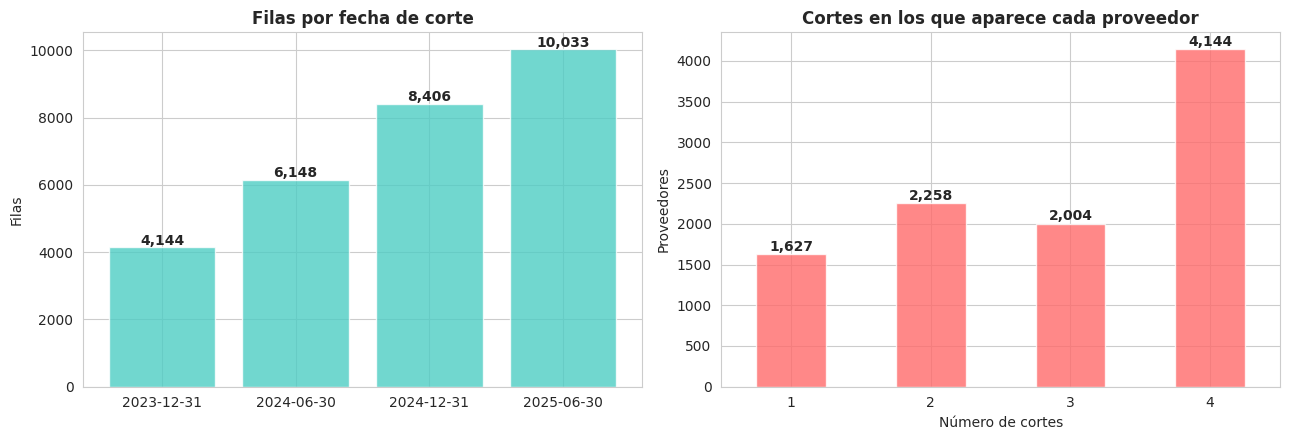

In [3]:
por_corte = df.groupby("fecha_corte").agg(
    filas=("id_proveedor", "size"),
    proveedores=("id_proveedor", "nunique"),
    positivos=("target", "sum"),
)
por_corte["prevalencia (%)"] = (por_corte["positivos"] / por_corte["filas"] * 100).round(2)
display(por_corte)

print("Proveedores distintos en todo el dataset:", f"{df['id_proveedor'].nunique():,}")

veces = df.groupby("id_proveedor").size().value_counts().sort_index()
display(veces.rename("proveedores").rename_axis("cortes en los que aparece").to_frame())

ids_por_corte = df.groupby("fecha_corte")["id_proveedor"].agg(set)
anidados = all(ids_por_corte.iloc[i] <= ids_por_corte.iloc[i + 1] for i in range(len(ids_por_corte) - 1))
print("Cada corte contiene a todos los proveedores del corte anterior:", anidados)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(por_corte.index.strftime("%Y-%m-%d"), por_corte["filas"], color=COLOR_0, alpha=0.8)
axes[0].set_title("Filas por fecha de corte", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Filas")
for i, v in enumerate(por_corte["filas"]):
    axes[0].text(i, v + 80, f"{v:,}", ha="center", fontweight="bold")

veces.plot(kind="bar", ax=axes[1], color=COLOR_1, alpha=0.8)
axes[1].set_title("Cortes en los que aparece cada proveedor", fontweight="bold")
axes[1].set_xticklabels(veces.index, rotation=0)
axes[1].set_xlabel("Número de cortes")
axes[1].set_ylabel("Proveedores")
for i, v in enumerate(veces):
    axes[1].text(i, v + 40, f"{v:,}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

**Qué observamos**

- El dataset tiene 28 731 filas, pero solo **10 033 proveedores distintos**: un mismo proveedor aparece hasta en cuatro cortes.
- Cada corte contiene a todos los proveedores del anterior, porque el historial es acumulativo: un proveedor que ya tenía contratos disponibles en un corte los sigue teniendo en los siguientes. Los 4 144 proveedores del primer corte aparecen en los cuatro.
- El número de filas crece de 4 144 a 10 033 entre el primer y el último corte, a medida que se suman proveedores nuevos.

**Por qué importa.** Las filas de un mismo proveedor en distintos cortes **no son independientes** entre sí. Si hiciéramos una partición aleatoria de filas, el mismo proveedor quedaría a la vez en entrenamiento y en prueba y las métricas saldrían infladas. Por eso la evaluación debe hacerse por **fecha de corte** (partición temporal), tal como se planteó en la propuesta.

## 4. Variable objetivo y desbalance de clases

El `target` vale 1 si el proveedor recibe una sanción (inhabilitación **o** multa) en los 12 meses posteriores al corte. También conservamos por separado `y_inhabilitacion_12m` y `y_multa_12m`. Un 0 significa únicamente que **no observamos** una sanción en las bases oficiales durante esa ventana; no equivale a afirmar que el proveedor no incumplió.

Ratio de desbalance: 36.5:1
Proveedores distintos con al menos un corte positivo: 487


,Clase,Cantidad,Porcentaje (%)
0,0,27964,97.33
1,1,767,2.67


,filas positivas
Solo inhabilitación,410
Solo multa,331
Ambas,26


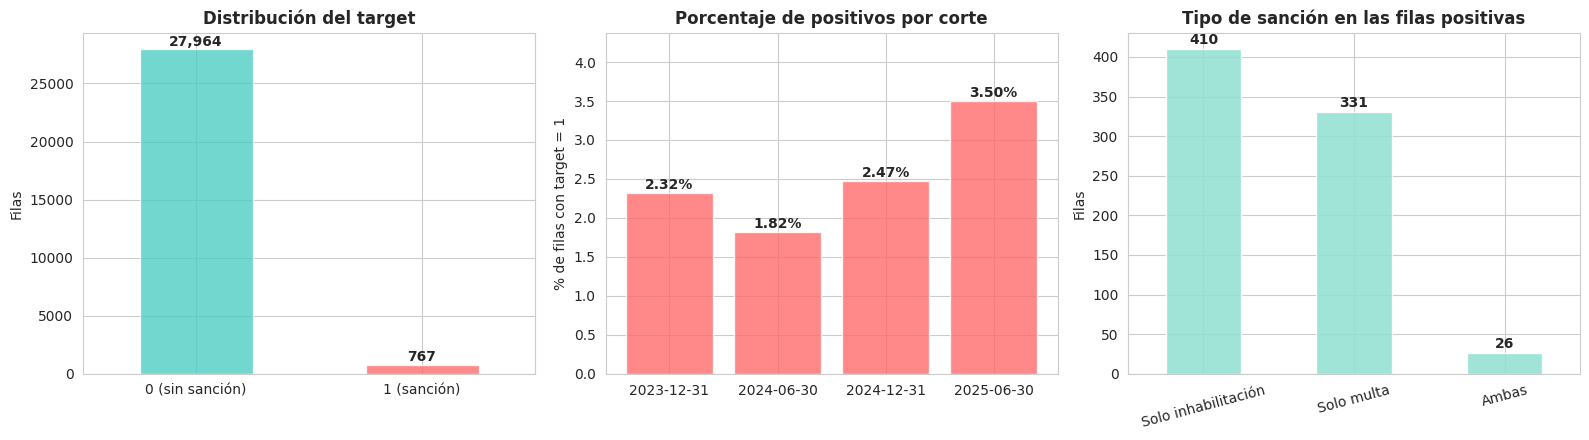

In [4]:
dist = df["target"].value_counts().sort_index()
tabla_target = pd.DataFrame({
    "Clase": dist.index,
    "Cantidad": dist.values,
    "Porcentaje (%)": (dist.values / len(df) * 100).round(2),
})
ratio = dist.max() / dist.min()
print(f"Ratio de desbalance: {ratio:.1f}:1")
print("Proveedores distintos con al menos un corte positivo:", df.loc[df["target"] == 1, "id_proveedor"].nunique())
display(tabla_target)

inh, mul = df["y_inhabilitacion_12m"] == 1, df["y_multa_12m"] == 1
tipos = pd.Series({
    "Solo inhabilitación": int((inh & ~mul).sum()),
    "Solo multa": int((~inh & mul).sum()),
    "Ambas": int((inh & mul).sum()),
})
display(tipos.rename("filas positivas").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

dist.plot(kind="bar", ax=axes[0], color=[COLOR_0, COLOR_1], alpha=0.8)
axes[0].set_title("Distribución del target", fontweight="bold")
axes[0].set_xticklabels(["0 (sin sanción)", "1 (sanción)"], rotation=0)
axes[0].set_xlabel("")
axes[0].set_ylabel("Filas")
for i, v in enumerate(dist):
    axes[0].text(i, v + 300, f"{v:,}", ha="center", fontweight="bold")

prev = por_corte["prevalencia (%)"]
axes[1].bar(prev.index.strftime("%Y-%m-%d"), prev.values, color=COLOR_1, alpha=0.8)
axes[1].set_title("Porcentaje de positivos por corte", fontweight="bold")
axes[1].set_ylabel("% de filas con target = 1")
for i, v in enumerate(prev):
    axes[1].text(i, v + 0.05, f"{v:.2f}%", ha="center", fontweight="bold")
axes[1].set_ylim(0, prev.max() * 1.25)

tipos.plot(kind="bar", ax=axes[2], color="#95E1D3", alpha=0.9)
axes[2].set_title("Tipo de sanción en las filas positivas", fontweight="bold")
axes[2].set_xticklabels(tipos.index, rotation=15)
axes[2].set_ylabel("Filas")
for i, v in enumerate(tipos):
    axes[2].text(i, v + 6, f"{v}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Qué observamos**

- Solo **767 de 28 731 filas (2,67 %)** son positivas: hay unas **36 filas sin sanción por cada una con sanción**. El desbalance es severo.
- Los 767 positivos corresponden a **487 proveedores distintos**: algunos se repiten como positivos en más de un corte.
- La sanción se reparte entre inhabilitaciones (436 filas) y multas (357), con apenas 26 filas que tienen ambas. Son eventos casi complementarios, por lo que el target combinado reúne dos tipos de sanción distintos.
- El porcentaje de positivos no es estable entre cortes: baja de 2,32 % a 1,82 % y luego sube a 2,47 % y 3,50 %. Lo retomamos en la sección 11.

**Por qué importa.**

- La exactitud (*accuracy*) no sirve como métrica: un modelo que siempre responda "sin sanción" acertaría el 97,3 % de las filas sin detectar ningún caso. Usaremos **PR-AUC** (métrica principal), recall, precision, F1 y ROC-AUC. La referencia mínima de PR-AUC es la prevalencia, cercana a 0,027.
- Para compensar el desbalance consideraremos pesos de clase y ajuste del umbral de decisión, y evaluaremos si el sobremuestreo con SMOTE aporta algo. Cualquier técnica de balanceo se aplicará **solo sobre el conjunto de entrenamiento**, nunca sobre validación o prueba.

## 5. Columnas de control

Además del target, el dataset trae columnas que no describen al proveedor sino al corte: `fecha_fin_ventana`, `ventana_etiqueta_completa`, `etiqueta_confiable` y `meses_cobertura_datos`. Revisamos qué información aportan realmente.

In [5]:
control_corte = (
    df.groupby("fecha_corte")[["fecha_fin_ventana", "ventana_etiqueta_completa", "etiqueta_confiable", "meses_cobertura_datos"]]
    .agg(lambda s: s.unique()[0] if s.nunique() == 1 else "varios")
)
display(control_corte)

constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Columnas con un único valor:", constantes)

,fecha_fin_ventana,ventana_etiqueta_completa,etiqueta_confiable,meses_cobertura_datos
fecha_corte,,,,
2023-12-31,2024-12-31,1,1,12.0
2024-06-30,2025-06-30,1,1,17.9
2024-12-31,2025-12-31,1,1,24.0
2025-06-30,2026-06-30,1,1,29.9


Columnas con un único valor: ['ventana_etiqueta_completa', 'etiqueta_confiable']


**Qué observamos**

- `ventana_etiqueta_completa` y `etiqueta_confiable` valen 1 en todas las filas: durante la construcción descartamos los cortes que no cumplían esas condiciones. Son **constantes** y no aportan información.
- `fecha_fin_ventana` y `meses_cobertura_datos` toman un único valor por corte (12, 18, 24 y 30 meses de cobertura aproximadamente). Es decir, **identifican el corte, no al proveedor**.

**Decisión.** Estas cuatro columnas, junto con `id_proveedor` y `fecha_corte`, se usarán para filtrar y auditar, pero **no como variables predictoras**. Tampoco se usarán `y_inhabilitacion_12m` ni `y_multa_12m`, porque son componentes del propio target.

## 6. Valores faltantes

Aplicamos el mismo análisis de faltantes por columna y por fila que vimos en clase. Un punto central es que, en este dataset, un valor nulo casi siempre **tiene un significado**: por ejemplo, no se puede calcular una desviación estándar con un solo contrato. Por eso primero entendemos de dónde salen los nulos y recién después decidimos cómo tratarlos.

,Columna,Faltantes,Porcentaje (%)
0,dias_desde_ultima_sancion,27306,95.04
1,crec_monto_12m,23474,81.70
2,crec_n_12m,23454,81.63
3,monto_pen_hist_std,21991,76.54
4,dias_prom_entre_contratos,21951,76.40
5,crec_monto_6m,19799,68.91
6,crec_n_6m,19767,68.80
7,monto_pen_hist_media,111,0.39
8,monto_pen_hist_max,111,0.39
9,monto_pen_hist_mediana,111,0.39


Columnas sin ningún nulo: 32 de 44
Filas con al menos un nulo: 99.74%


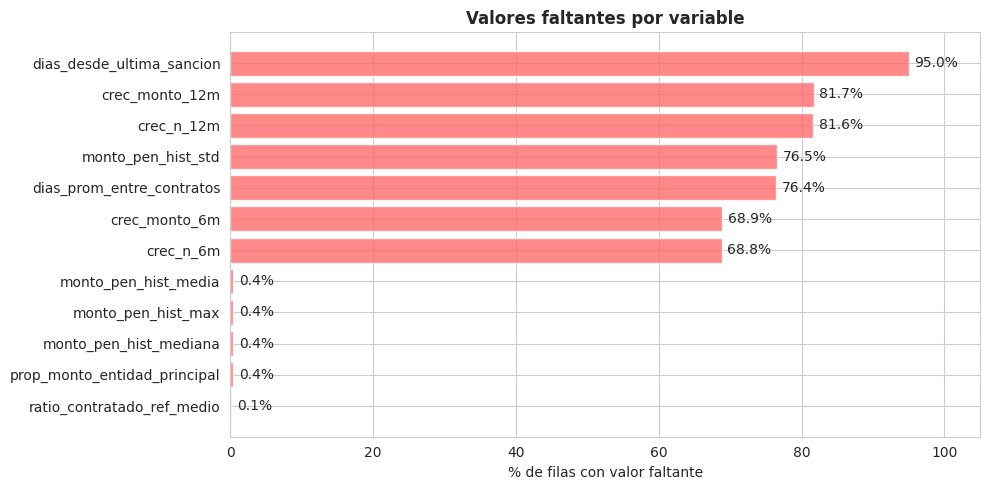

In [6]:
faltantes = df[PREDICTORAS].isna().sum()
faltantes_df = pd.DataFrame({
    "Columna": faltantes.index,
    "Faltantes": faltantes.values,
    "Porcentaje (%)": (faltantes.values / len(df) * 100).round(2),
})
faltantes_df = faltantes_df[faltantes_df["Faltantes"] > 0].sort_values("Faltantes", ascending=False).reset_index(drop=True)
display(faltantes_df)

print("Columnas sin ningún nulo:", len(PREDICTORAS) - len(faltantes_df), "de", len(PREDICTORAS))
print("Filas con al menos un nulo:", f"{df[PREDICTORAS].isna().any(axis=1).mean() * 100:.2f}%")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(faltantes_df["Columna"][::-1], faltantes_df["Porcentaje (%)"][::-1], color=COLOR_1, alpha=0.8)
ax.set_xlabel("% de filas con valor faltante")
ax.set_title("Valores faltantes por variable", fontweight="bold")
for i, v in enumerate(faltantes_df["Porcentaje (%)"][::-1]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 105)
plt.tight_layout()
plt.show()

In [7]:
faltantes_fila = df[PREDICTORAS].isna().sum(axis=1)
conteo_fila = faltantes_fila.value_counts().sort_index()
fila_stats_df = pd.DataFrame({
    "Num. faltantes": conteo_fila.index,
    "Filas": conteo_fila.values,
    "Porcentaje (%)": (conteo_fila.values / len(df) * 100).round(2),
})
display(fila_stats_df)

,Num. faltantes,Filas,Porcentaje (%)
0,0,76,0.26
1,1,749,2.61
2,2,342,1.19
3,3,3194,11.12
4,4,544,1.89
5,5,10826,37.68
6,6,495,1.72
7,7,12379,43.09
8,8,17,0.06
9,9,13,0.05


**Origen de los nulos.** Comprobamos que casi todos son **estructurales** (se deben a cómo se define la variable) y no errores de captura.

In [8]:
estructurales = pd.DataFrame([
    {
        "variable": "monto_pen_hist_std",
        "regla": "nulo si el proveedor tiene un solo contrato",
        "nulos_con_regla": int((df["monto_pen_hist_std"].isna() & (df["n_contratos_hist"] == 1)).sum()),
        "nulos_totales": int(df["monto_pen_hist_std"].isna().sum()),
    },
    {
        "variable": "dias_prom_entre_contratos",
        "regla": "nulo si el proveedor tiene un solo contrato",
        "nulos_con_regla": int((df["dias_prom_entre_contratos"].isna() & (df["n_contratos_hist"] == 1)).sum()),
        "nulos_totales": int(df["dias_prom_entre_contratos"].isna().sum()),
    },
    {
        "variable": "dias_desde_ultima_sancion",
        "regla": "nulo si no tiene sanción previa",
        "nulos_con_regla": int((df["dias_desde_ultima_sancion"].isna() & (df["tiene_sancion_previa"] == 0)).sum()),
        "nulos_totales": int(df["dias_desde_ultima_sancion"].isna().sum()),
    },
    {
        "variable": "monto_pen_hist_media / mediana / max, prop_monto_entidad_principal",
        "regla": "nulo si el monto histórico en soles es 0",
        "nulos_con_regla": int((df["monto_pen_hist_media"].isna() & (df["monto_pen_hist_total"] == 0)).sum()),
        "nulos_totales": int(df["monto_pen_hist_media"].isna().sum()),
    },
])
display(estructurales)

previo_6m = df["n_contratos_12m"] - df["n_contratos_6m"]
previo_12m = df["n_contratos_24m"] - df["n_contratos_12m"]
c6 = df["fecha_corte"] > df["fecha_corte"].min()
c12 = df["fecha_corte"] >= pd.Timestamp("2025-06-30")
print("crec_n_6m es nulo exactamente cuando el semestre previo no tuvo contratos (cortes con cobertura):",
      bool((df.loc[c6, "crec_n_6m"].isna() == (previo_6m[c6] == 0)).all()))
print("crec_n_12m es nulo exactamente cuando el año previo no tuvo contratos (cortes con cobertura):",
      bool((df.loc[c12, "crec_n_12m"].isna() == (previo_12m[c12] == 0)).all()))

cols_crec = ["crec_n_6m", "crec_monto_6m", "crec_n_12m", "crec_monto_12m"]
display(df.groupby("fecha_corte")[cols_crec].apply(lambda g: (g.isna().mean() * 100).round(1)))

,variable,regla,nulos_con_regla,nulos_totales
0,monto_pen_hist_std,nulo si el proveedor tiene un solo contrato,21951,21991
1,dias_prom_entre_contratos,nulo si el proveedor tiene un solo contrato,21951,21951
2,dias_desde_ultima_sancion,nulo si no tiene sanción previa,27306,27306
3,"monto_pen_hist_media / mediana / max, prop_mon...",nulo si el monto histórico en soles es 0,111,111


crec_n_6m es nulo exactamente cuando el semestre previo no tuvo contratos (cortes con cobertura): True
crec_n_12m es nulo exactamente cuando el año previo no tuvo contratos (cortes con cobertura): True


,crec_n_6m,crec_monto_6m,crec_n_12m,crec_monto_12m
fecha_corte,,,,
2023-12-31,100.0,100.0,100.0,100.0
2024-06-30,49.7,49.8,100.0,100.0
2024-12-31,67.6,67.8,100.0,100.0
2025-06-30,68.6,68.7,47.4,47.6


**Qué observamos**

- De las 44 variables predictoras, **12 tienen nulos**. Las demás están completas.
- Los nulos grandes son estructurales:
  - `monto_pen_hist_std` (76,5 %) y `dias_prom_entre_contratos` (76,4 %) solo existen cuando el proveedor tiene **al menos dos contratos**; el 76,4 % de las filas tiene un único contrato. En la desviación estándar hay además 40 nulos de proveedores con varios contratos pero un solo monto válido en soles.
  - `dias_desde_ultima_sancion` (95,0 %) es nulo exactamente en los proveedores **sin sanción previa**; la regla se cumple en todas las filas.
  - Las variables de **crecimiento** (68,8 % a 81,7 %) son nulas cuando el periodo anterior no tuvo contratos (no se puede dividir entre cero) o cuando los datos no alcanzan para ese periodo. Por eso `crec_*_12m` es nulo en todas las filas de los tres primeros cortes y `crec_*_6m` en todo el primero: los datos de contratos empiezan en 2023 y no alcanzan para comparar contra un periodo anterior.
  - El 0,4 % restante (111 filas) corresponde a proveedores cuyos contratos están todos en moneda extranjera o sin monto en soles, por lo que el monto histórico es 0 y no se pueden calcular media, mediana, máximo ni concentración de monto. Otras 30 filas no tienen `ratio_contratado_ref_medio` por falta de monto referencial válido.
- **El 99,7 % de las filas tiene al menos un nulo**, y la gran mayoría (80,8 %) tiene 5 o 7: los 3 nulos de un proveedor con un solo contrato y sin sanción previa, más 2 o 4 nulos de las variables de crecimiento. Solo 76 filas (0,26 %) están completas.

**Por qué importa.** La opción de eliminar filas con faltantes (*dropna*) es inviable: nos quedaríamos con 76 filas (0,26 %) y apenas 14 de los 767 positivos. Eliminar las columnas más incompletas tampoco es buena idea, porque `dias_desde_ultima_sancion` y las variables de crecimiento tienen significado de negocio. Los nulos de este dataset no son aleatorios, así que imputar con la media sin criterio mezclaría "no aplica" con "valor típico".

**Decisión.** Mantenemos los nulos sin imputar en el dataset procesado. En `02_modelos` los trataremos **después de dividir en entrenamiento y prueba**, ajustando la imputación solo con entrenamiento y comparando las técnicas vistas en clase (media, mediana, KNN). Para las variables con significado estructural evaluaremos además agregar un indicador de "dato no disponible" (por ejemplo, `tiene_sancion_previa` ya cumple ese papel para `dias_desde_ultima_sancion`). Los modelos basados en árboles pueden tolerar mejor esta estructura que KNN, regresión logística o MLP.

## 7. Escalas de las variables

Revisamos el rango de cada variable continua. Variables con escalas muy distintas afectan a los modelos que usan distancias o gradientes.

,Variable,Mín,Mediana,Máx,Rango
0,monto_pen_24m,0.00,"540,000.00","1,048,377,240.13","1,048,377,240.13"
1,monto_pen_hist_total,0.00,"566,800.00","1,048,377,240.13","1,048,377,240.13"
2,monto_pen_3m,0.00,0.00,"806,093,923.08","806,093,923.08"
3,monto_pen_6m,0.00,0.00,"806,093,923.08","806,093,923.08"
4,monto_pen_12m,0.00,"213,516.17","806,093,923.08","806,093,923.08"
5,monto_pen_hist_media,"11,989.08","426,924.06","806,093,923.08","806,081,934.00"
6,monto_pen_hist_mediana,"11,989.08","408,407.67","806,093,923.08","806,081,934.00"
7,monto_pen_hist_max,"15,000.00","481,375.30","806,093,923.08","806,078,923.08"
8,monto_pen_hist_std,0.00,"214,170.92","403,184,335.51","403,184,335.51"
9,duracion_contrato_dias_medio,1.00,181.67,"9,034.00","9,033.00"


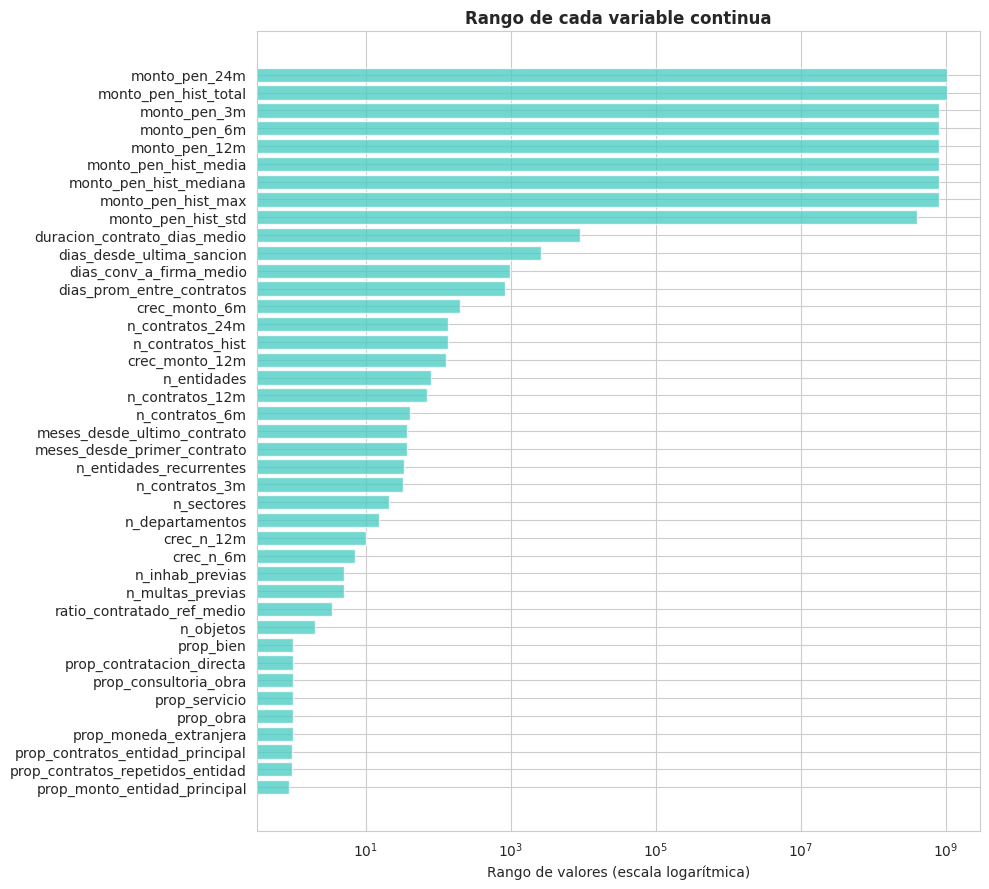

In [9]:
variables_escala = [c for c in CONTINUAS]
escalas = pd.DataFrame({
    "Variable": variables_escala,
    "Mín": df[variables_escala].min().values,
    "Mediana": df[variables_escala].median().values,
    "Máx": df[variables_escala].max().values,
})
escalas["Rango"] = escalas["Máx"] - escalas["Mín"]
escalas = escalas.sort_values("Rango", ascending=False).reset_index(drop=True)
pd.options.display.float_format = "{:,.2f}".format
display(escalas)
pd.reset_option("display.float_format")

fig, ax = plt.subplots(figsize=(10, 9))
y_pos = np.arange(len(escalas))
ax.barh(y_pos, escalas["Rango"].clip(lower=1e-3), color=COLOR_0, alpha=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(escalas["Variable"])
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("Rango de valores (escala logarítmica)")
ax.set_title("Rango de cada variable continua", fontweight="bold")
plt.tight_layout()
plt.show()

**Qué observamos.** Las escalas son muy heterogéneas. Los montos en soles llegan a cientos de millones (el máximo de `monto_pen_24m` supera los 1 000 millones), los días y duraciones van de decenas a miles, los conteos de contratos a decenas o cientos y las proporciones están entre 0 y 1. Entre la variable de mayor rango y las proporciones hay una diferencia de cerca de **nueve órdenes de magnitud**.

**Por qué importa.** KNN calcula distancias, y la regresión logística y el MLP se optimizan por gradiente: sin escalar, las variables de monto dominarían por completo a las demás. Los árboles de decisión no se ven afectados por la escala.

**Decisión.** Para KNN, regresión logística y MLP aplicaremos estandarización (`StandardScaler`) o normalización (`MinMaxScaler`), **ajustando el escalador únicamente con entrenamiento**, y compararemos ambas. Dado el sesgo de los montos (sección 8), el escalado se combinará con el tratamiento de valores atípicos de la sección 9.

## 8. Distribuciones

Revisamos la forma de las variables más representativas. En las que tienen colas muy largas usamos escala logarítmica para poder ver la distribución completa.

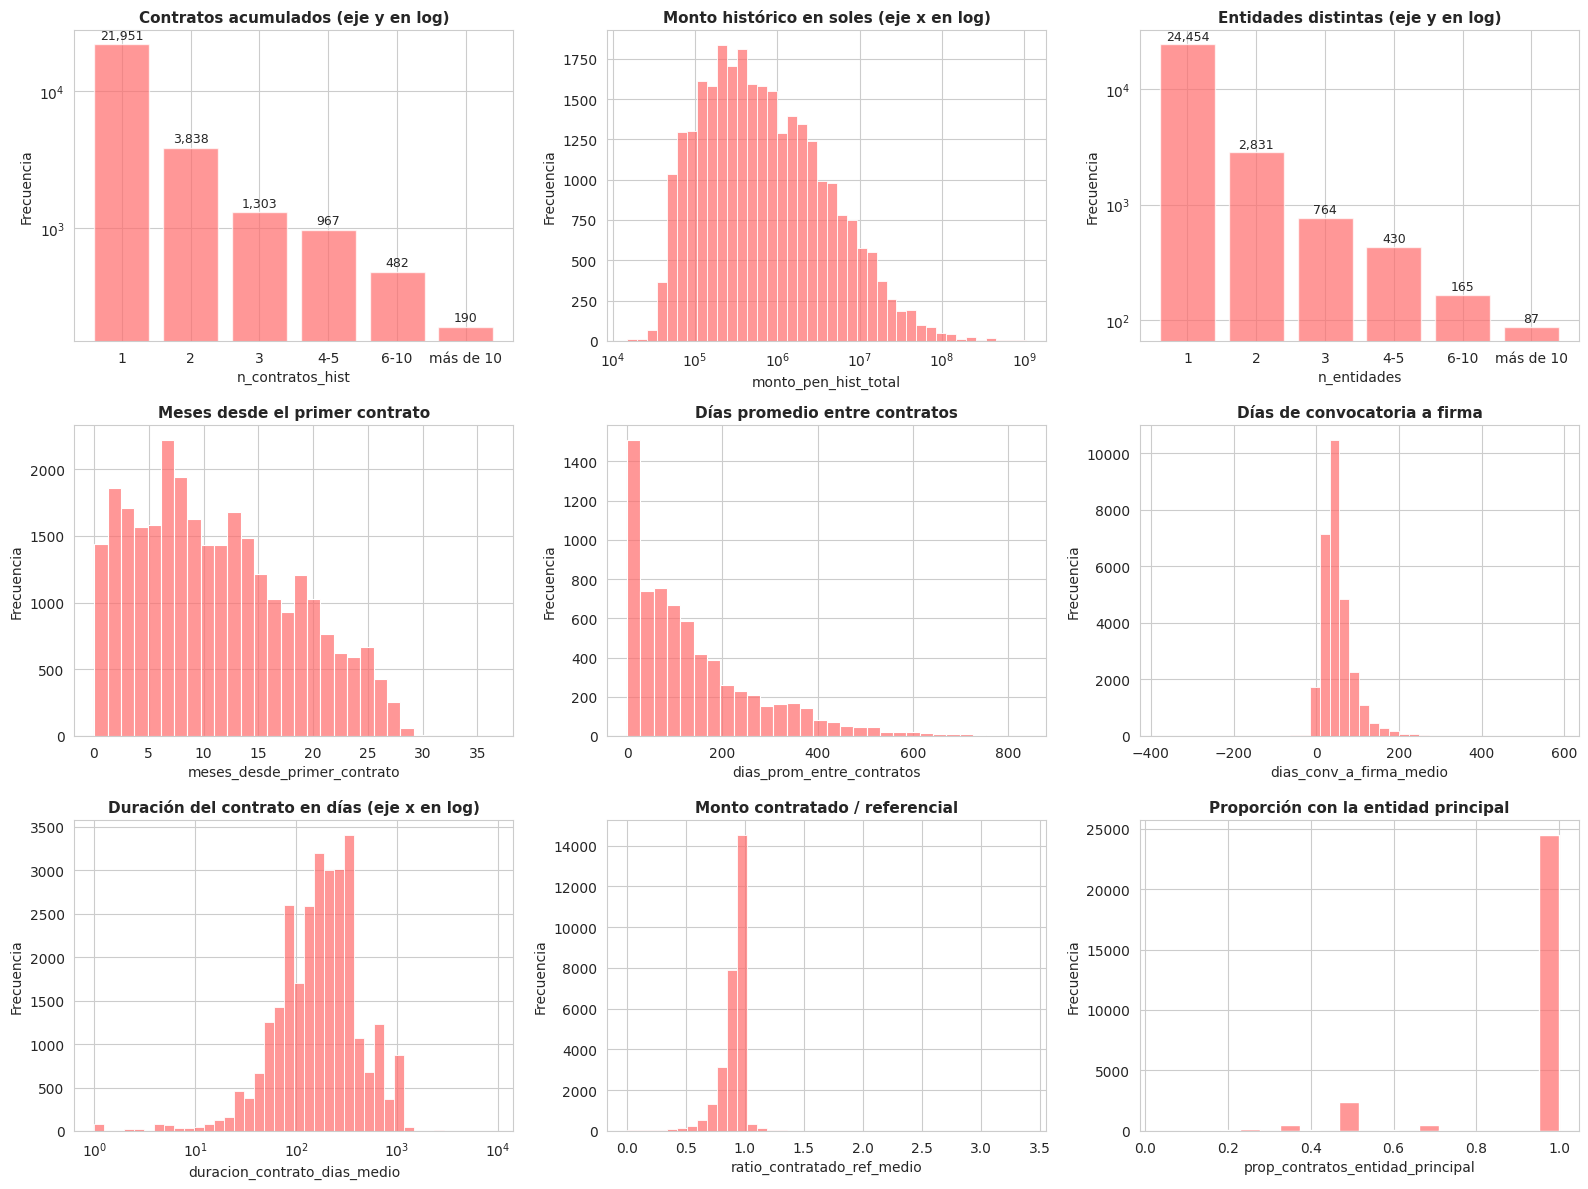

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

TRAMOS_CONTEO = [0, 1, 2, 3, 5, 10, 1000]
ETIQUETAS_CONTEO = ["1", "2", "3", "4-5", "6-10", "más de 10"]
conteo_paneles = {
    "n_contratos_hist": "Contratos acumulados (eje y en log)",
    "n_entidades": "Entidades distintas (eje y en log)",
}

paneles = [
    ("n_contratos_hist", None, None, None),
    ("monto_pen_hist_total", "Monto histórico en soles (eje x en log)", dict(log_scale=True, bins=40), lambda s: s[s > 0]),
    ("n_entidades", None, None, None),
    ("meses_desde_primer_contrato", "Meses desde el primer contrato", dict(bins=30), None),
    ("dias_prom_entre_contratos", "Días promedio entre contratos", dict(bins=30), None),
    ("dias_conv_a_firma_medio", "Días de convocatoria a firma", dict(bins=40), None),
    ("duracion_contrato_dias_medio", "Duración del contrato en días (eje x en log)", dict(log_scale=True, bins=40), lambda s: s[s > 0]),
    ("ratio_contratado_ref_medio", "Monto contratado / referencial", dict(bins=40), None),
    ("prop_contratos_entidad_principal", "Proporción con la entidad principal", dict(bins=20), None),
]
for ax, (col, titulo, kwargs, filtro) in zip(axes, paneles):
    if col in conteo_paneles:
        frec = pd.cut(df[col], TRAMOS_CONTEO, labels=ETIQUETAS_CONTEO).value_counts().reindex(ETIQUETAS_CONTEO)
        ax.bar(ETIQUETAS_CONTEO, frec.values, color=COLOR_1, alpha=0.7)
        ax.set_yscale("log")
        for i, v in enumerate(frec.values):
            ax.text(i, v * 1.1, f"{v:,}", ha="center", fontsize=9)
        ax.set_title(conteo_paneles[col], fontweight="bold", fontsize=11)
    else:
        serie = df[col].dropna()
        if filtro is not None:
            serie = filtro(serie)
        sns.histplot(x=serie, ax=ax, color=COLOR_1, alpha=0.7, **kwargs)
        ax.set_title(titulo, fontweight="bold", fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

,prop_bien,prop_servicio,prop_obra,prop_consultoria_obra
No consorcio,30.8,55.3,10.5,3.4
Consorcio probable,3.1,19.1,63.3,14.5


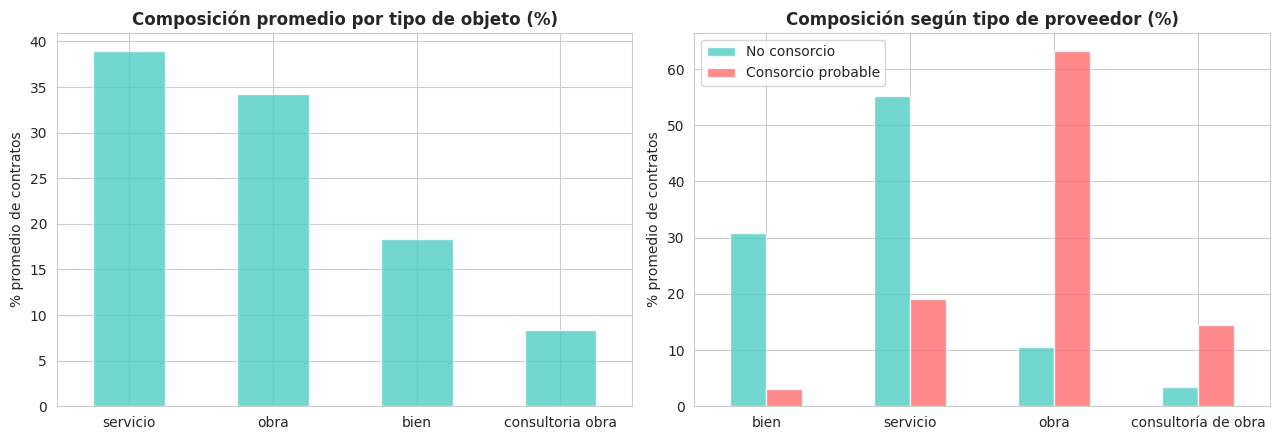

In [11]:
composicion = df[["prop_bien", "prop_servicio", "prop_obra", "prop_consultoria_obra"]].mean().sort_values(ascending=False)
por_consorcio = df.groupby("es_consorcio_probable")[["prop_bien", "prop_servicio", "prop_obra", "prop_consultoria_obra"]].mean()
por_consorcio.index = ["No consorcio", "Consorcio probable"]
display((por_consorcio * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(composicion * 100).plot(kind="bar", ax=axes[0], color=COLOR_0, alpha=0.8)
axes[0].set_title("Composición promedio por tipo de objeto (%)", fontweight="bold")
axes[0].set_xticklabels(composicion.index.str.replace("prop_", "").str.replace("_", " "), rotation=0)
axes[0].set_xlabel("")
axes[0].set_ylabel("% promedio de contratos")
(por_consorcio * 100).T.plot(kind="bar", ax=axes[1], color=[COLOR_0, COLOR_1], alpha=0.8)
axes[1].set_title("Composición según tipo de proveedor (%)", fontweight="bold")
axes[1].set_xticklabels(["bien", "servicio", "obra", "consultoría de obra"], rotation=0)
axes[1].set_ylabel("% promedio de contratos")
plt.tight_layout()
plt.show()

**Qué observamos**

- **Casi todas las variables de conteo y monto tienen sesgo a la derecha** con colas muy largas. La gran mayoría de los proveedores tiene un solo contrato y un monto modesto, mientras que unos pocos concentran decenas de contratos o montos de cientos de millones. La mediana de `n_contratos_hist` es 1 y su máximo es 136.
- Los **montos** son aproximadamente log-normales: en escala logarítmica la distribución se vuelve razonablemente simétrica, con la mayor parte entre cien mil y unos pocos millones de soles. Lo mismo ocurre con la duración de los contratos, que se concentra entre unos 100 y 400 días.
- El **tiempo desde el primer contrato** va de 0 a unos 36 meses (la mayoría por debajo de 30) y decrece de forma suave, consistente con el ingreso continuo de proveedores nuevos y con los datos que empiezan en 2023.
- **Concentración:** como el 76,4 % de las filas tiene un solo contrato, `prop_contratos_entidad_principal` vale exactamente 1 en una gran masa de filas. Es una consecuencia de la estructura y no un indicador de que el proveedor dependa de una entidad.
- `ratio_contratado_ref_medio` se concentra cerca de 0,9 a 1,0: los contratos se adjudican típicamente cerca o por debajo del monto referencial.
- `dias_conv_a_firma_medio` se concentra entre 0 y 100 días, con cola derecha y algunos valores negativos (sección 9).
- **Composición:** el promedio de contratos es 39 % servicios, 34 % obras, 18 % bienes y 8 % consultorías de obra. Los consorcios probables son muy distintos: en promedio el 63 % de sus contratos son obras, frente al 10,5 % de los demás proveedores. Esto es coherente con la hipótesis de que muchos de esos códigos corresponden a consorcios formados para una obra.

**Por qué importa.** El sesgo y los ceros inflados refuerzan la necesidad de escalar y de tener cuidado con los valores extremos. También anticipan que muchas variables serán poco informativas para el 76 % de las filas que solo tiene un contrato.

## 9. Calidad de datos y valores atípicos

### 9.1 Comprobaciones de coherencia

Antes de buscar valores atípicos estadísticos, revisamos casos que no tienen sentido lógico o que merecen atención.

In [12]:
coherencia = pd.DataFrame([
    ("Días entre convocatoria y firma negativos (firma anterior a la convocatoria)", int((df["dias_conv_a_firma_medio"] < 0).sum())),
    ("Monto contratado mayor que el referencial (ratio > 1)", int((df["ratio_contratado_ref_medio"] > 1).sum())),
    ("Duración media de contrato mayor a 5 años (> 1 825 días)", int((df["duracion_contrato_dias_medio"] > 1825).sum())),
    ("Monto histórico en soles igual a 0", int((df["monto_pen_hist_total"] == 0).sum())),
    ("Proveedores con 0 departamentos identificados", int((df["n_departamentos"] == 0).sum())),
    ("Proporciones fuera del rango [0, 1]", int(((df.filter(like="prop_") < 0) | (df.filter(like="prop_") > 1)).any(axis=1).sum())),
    ("Filas duplicadas por (proveedor, corte)", int(df.duplicated(["id_proveedor", "fecha_corte"]).sum())),
], columns=["Comprobación", "Filas"])
coherencia["Porcentaje (%)"] = (coherencia["Filas"] / len(df) * 100).round(2)
display(coherencia)
print("Duración máxima observada:", f"{df['duracion_contrato_dias_medio'].max():,.0f} días", f"(~{df['duracion_contrato_dias_medio'].max() / 365:.1f} años)")
print("Ratio contratado/referencial máximo:", round(df["ratio_contratado_ref_medio"].max(), 2))

,Comprobación,Filas,Porcentaje (%)
0,Días entre convocatoria y firma negativos (fir...,132,0.46
1,Monto contratado mayor que el referencial (rat...,734,2.55
2,Duración media de contrato mayor a 5 años (> 1...,9,0.03
3,Monto histórico en soles igual a 0,111,0.39
4,Proveedores con 0 departamentos identificados,4,0.01
5,"Proporciones fuera del rango [0, 1]",0,0.00
6,"Filas duplicadas por (proveedor, corte)",0,0.00


Duración máxima observada: 9,034 días (~24.8 años)
Ratio contratado/referencial máximo: 3.38


**Qué observamos y decidimos**

- **132 filas (0,46 %) tienen días de convocatoria a firma negativos**: en promedio, el contrato figura firmado antes de la fecha de convocatoria. Puede deberse a errores de registro o a procesos particulares; no tenemos evidencia suficiente para distinguirlos. No las corregimos ni las eliminamos, y lo registramos como limitación.
- **734 filas (2,55 %) tienen un monto contratado mayor al referencial** (máximo de 3,38 veces). Podría ser un caso real o una inconsistencia de montos entre contrato y convocatoria; tampoco lo corregimos.
- **111 filas tienen monto histórico en soles igual a 0**: son proveedores con contratos solo en otra moneda o sin monto válido. No son errores; es el efecto de no convertir monedas.
- Hay **9 filas con duración media mayor a 5 años** (máximo cercano a 25 años), que probablemente son errores de fecha de vigencia. Son pocas y no afectan el análisis general.
- **4 filas no tienen ningún departamento identificado**, probablemente porque la entidad no se pudo ubicar en el cruce con el listado de entidades.
- No hay proporciones fuera de [0, 1] ni filas repetidas por `(proveedor, corte)`.

### 9.2 Detección estadística de valores atípicos

Aplicamos los dos métodos vistos en clase, **z-score (|z| > 3)** e **IQR (1,5 × IQR)**, sobre las variables continuas. Excluimos las proporciones (`prop_*`) porque están acotadas entre 0 y 1: con tantas filas en exactamente 0 o 1, el rango intercuartílico se colapsa y el método IQR marcaría como atípicos valores perfectamente normales.

In [13]:
continuas_outliers = [c for c in CONTINUAS if not c.startswith("prop_")]

z_scores = pd.DataFrame(
    np.abs(stats.zscore(df[continuas_outliers], nan_policy="omit")),
    columns=continuas_outliers,
)
outliers_z = z_scores > 3

Q1 = df[continuas_outliers].quantile(0.25)
Q3 = df[continuas_outliers].quantile(0.75)
IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR
outliers_iqr = (df[continuas_outliers] < limite_inf) | (df[continuas_outliers] > limite_sup)

resumen_outliers = pd.DataFrame({
    "Variable": continuas_outliers,
    "Outliers z-score": outliers_z.sum().values,
    "% z-score": (outliers_z.mean() * 100).round(2).values,
    "Outliers IQR": outliers_iqr.sum().values,
    "% IQR": (outliers_iqr.mean() * 100).round(2).values,
}).sort_values("Outliers IQR", ascending=False).reset_index(drop=True)
display(resumen_outliers.head(15))

print("Mediana del % de outliers entre variables -> z-score:", resumen_outliers["% z-score"].median(),
      "| IQR:", resumen_outliers["% IQR"].median())
print("Filas con algún outlier por z-score:", f"{outliers_z.any(axis=1).mean() * 100:.1f}%",
      "| por IQR:", f"{outliers_iqr.any(axis=1).mean() * 100:.1f}%")

,Variable,Outliers z-score,% z-score,Outliers IQR,% IQR
0,n_contratos_24m,262,0.91,7244,25.21
1,n_contratos_3m,247,0.86,6818,23.73
2,monto_pen_3m,110,0.38,6796,23.65
3,n_contratos_hist,293,1.02,6780,23.60
4,monto_pen_6m,158,0.55,4928,17.15
5,n_entidades,252,0.88,4277,14.89
6,monto_pen_12m,186,0.65,4087,14.23
7,n_entidades_recurrentes,357,1.24,3949,13.74
8,monto_pen_24m,225,0.78,3909,13.61
9,monto_pen_hist_max,243,0.85,3877,13.49


Mediana del % de outliers entre variables -> z-score: 0.855 | IQR: 6.1
Filas con algún outlier por z-score: 17.0% | por IQR: 62.6%


**Qué observamos.** El criterio IQR marca muchísimos más valores que el z-score: en conteos y montos, entre el 13 % y el 25 % de las filas por variable, y en conjunto el 62,6 % de las filas tiene algún valor atípico por IQR frente al 17,0 % por z-score. Eso ocurre porque estas variables tienen una gran masa en 0 o 1 y una cola muy larga, de modo que el rango intercuartílico es muy estrecho. El z-score es más conservador (cerca o por debajo del 1 % en la mayoría de variables), pero también está distorsionado por la propia cola larga, que infla la desviación estándar.

Para decidir qué hacer con estos valores revisamos si los extremos tienen un comportamiento distinto en cuanto a sanciones.

In [14]:
vars_revisar = ["n_contratos_hist", "n_entidades", "monto_pen_12m", "monto_pen_hist_max", "dias_conv_a_firma_medio", "duracion_contrato_dias_medio"]
filas = []
for col in vars_revisar:
    marca = outliers_z[col].to_numpy()
    filas.append({
        "Variable": col,
        "Filas outlier (z>3)": int(marca.sum()),
        "% target en outliers": round(df["target"].to_numpy()[marca].mean() * 100, 2),
        "% target en el resto": round(df["target"].to_numpy()[~marca].mean() * 100, 2),
    })
display(pd.DataFrame(filas))

,Variable,Filas outlier (z>3),% target en outliers,% target en el resto
0,n_contratos_hist,293,8.53,2.61
1,n_entidades,252,12.30,2.58
2,monto_pen_12m,186,5.38,2.65
3,monto_pen_hist_max,243,5.76,2.64
4,dias_conv_a_firma_medio,474,6.33,2.61
5,duracion_contrato_dias_medio,894,2.68,2.67


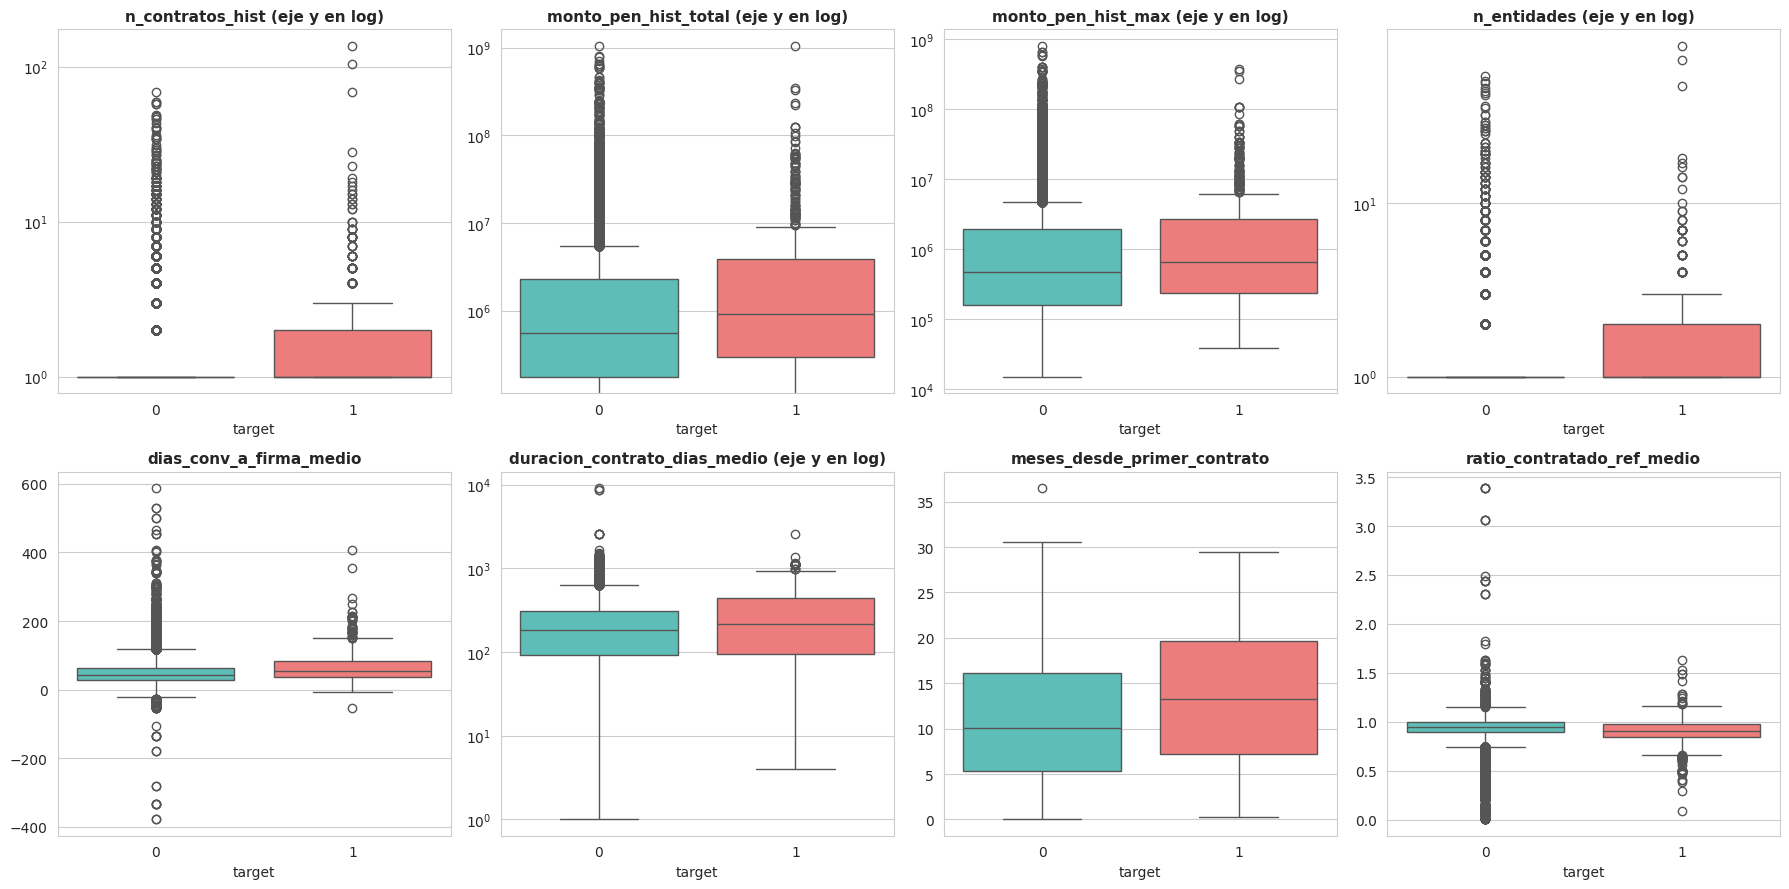

In [15]:
vars_box = [
    ("n_contratos_hist", True), ("monto_pen_hist_total", True), ("monto_pen_hist_max", True), ("n_entidades", True),
    ("dias_conv_a_firma_medio", False), ("duracion_contrato_dias_medio", True),
    ("meses_desde_primer_contrato", False), ("ratio_contratado_ref_medio", False),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, (col, log) in zip(axes.flatten(), vars_box):
    sns.boxplot(data=df, x="target", y=col, ax=ax, palette=[COLOR_0, COLOR_1], hue="target", legend=False)
    if log:
        ax.set_yscale("log")
    ax.set_title(col + (" (eje y en log)" if log else ""), fontweight="bold", fontsize=11)
    ax.set_xlabel("target")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Qué observamos**

- Los valores extremos **no son ruido**: en varias variables, las filas con valores extremos tienen una proporción de positivos mucho mayor que el resto. Por ejemplo, entre los proveedores con un número atípico de entidades distintas (z > 3), el 12,3 % recibe una sanción, frente al 2,6 % del resto; con `n_contratos_hist` atípico es 8,5 % contra 2,6 %. En `duracion_contrato_dias_medio` no hay diferencia (2,7 % en ambos), lo que es coherente con los pocos casos de errores de fecha.
- Los diagramas de caja por clase muestran que los positivos tienden a tener más contratos, más entidades, montos más altos y más antigüedad, y un ratio contratado/referencial algo menor, con colas largas en ambas clases.

**Decisión.** **No eliminaremos filas por valores atípicos.** Son proveedores grandes reales y concentran una parte importante de los positivos; descartarlos eliminaría justo la señal que buscamos y reduciría aún más la clase minoritaria. Para los modelos sensibles a escala (KNN, regresión logística, MLP) evaluaremos limitar los extremos con *clipping* por IQR, con límites calculados solo en entrenamiento, y lo compararemos contra no limitarlos. Los árboles se usarán sin tratar los extremos.

## 10. Relación de las variables con el target

Con el diagnóstico de calidad hecho, miramos qué variables muestran señal frente a la sanción futura. Se trata de relaciones **descriptivas y univariadas**: no implican causalidad ni demuestran que un proveedor haya incumplido.

### 10.1 Tasa de sanción por grupos

La tasa es el porcentaje de filas con `target = 1` dentro de cada grupo.

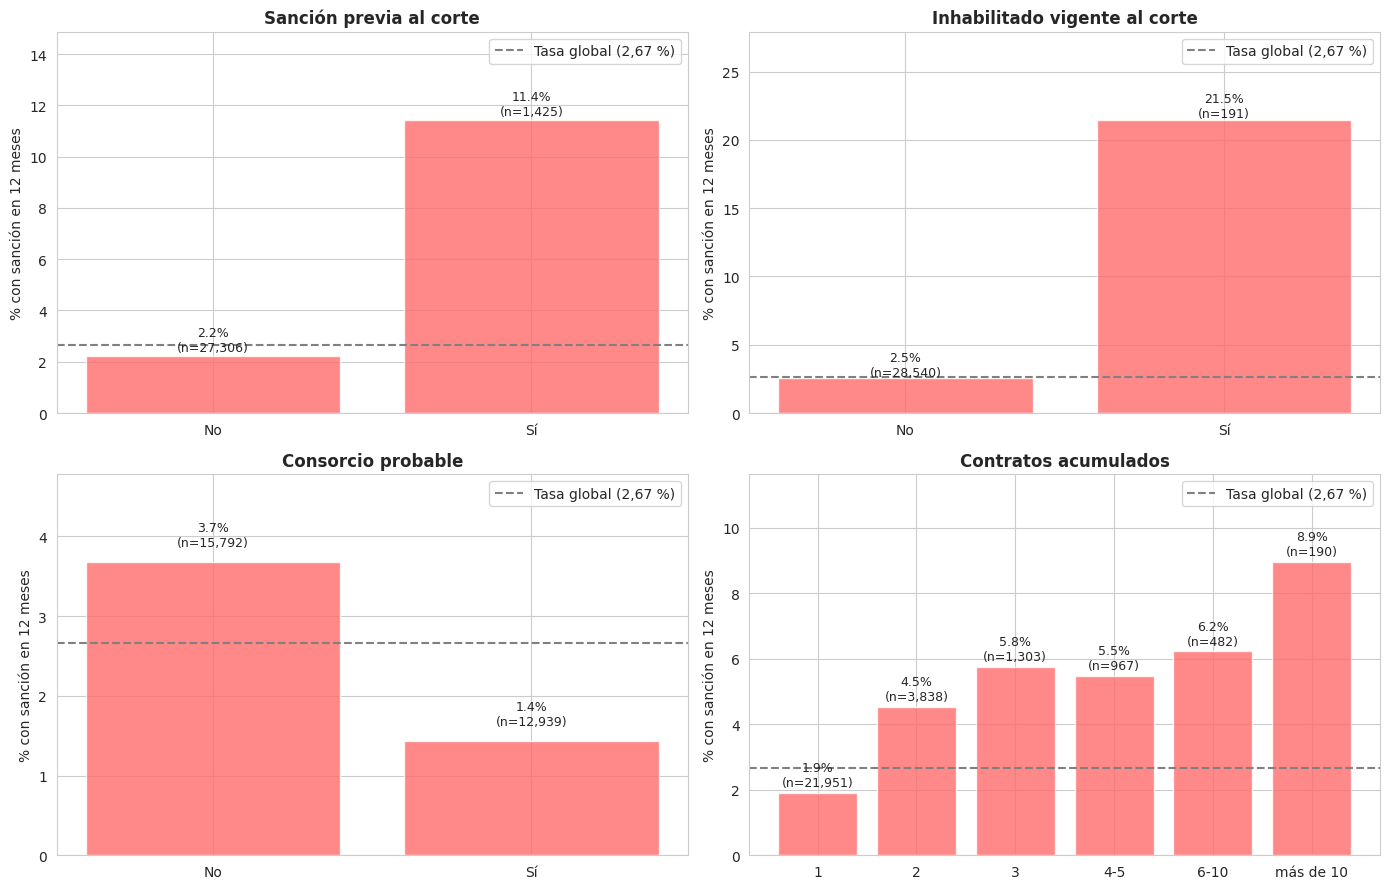

,tasa_%,positivos,filas
Sanción previa al corte,,,
No,2.21,604,27306
Sí,11.44,163,1425


,tasa_%,positivos,filas
Inhabilitado vigente al corte,,,
No,2.54,726,28540
Sí,21.47,41,191


,tasa_%,positivos,filas
Consorcio probable,,,
No,3.68,581,15792
Sí,1.44,186,12939


,tasa_%,positivos,filas
Contratos acumulados,,,
1,1.90,418,21951
2,4.53,174,3838
3,5.76,75,1303
4-5,5.48,53,967
6-10,6.22,30,482
más de 10,8.95,17,190


In [16]:
def tasa_por(serie, nombre):
    t = df.groupby(serie, observed=True)["target"].agg(["mean", "sum", "size"])
    t["mean"] = t["mean"] * 100
    t.index = t.index.astype(str)
    t.index.name = nombre
    return t.rename(columns={"mean": "tasa_%", "sum": "positivos", "size": "filas"})


tramos = pd.cut(df["n_contratos_hist"], [0, 1, 2, 3, 5, 10, 1000], labels=["1", "2", "3", "4-5", "6-10", "más de 10"])
grupos_tasa = [
    (df["tiene_sancion_previa"].map({0: "No", 1: "Sí"}), "Sanción previa al corte"),
    (df["inhabilitado_vigente_al_corte"].map({0: "No", 1: "Sí"}), "Inhabilitado vigente al corte"),
    (df["es_consorcio_probable"].map({0: "No", 1: "Sí"}), "Consorcio probable"),
    (tramos, "Contratos acumulados"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
tablas_tasa = []
for ax, (serie, nombre) in zip(axes.flatten(), grupos_tasa):
    t = tasa_por(serie, nombre)
    tablas_tasa.append(t)
    ax.bar(t.index, t["tasa_%"], color=COLOR_1, alpha=0.8)
    ax.axhline(df["target"].mean() * 100, color="gray", linestyle="--", label="Tasa global (2,67 %)")
    ax.set_title(nombre, fontweight="bold")
    ax.set_ylabel("% con sanción en 12 meses")
    for i, (tasa, n) in enumerate(zip(t["tasa_%"], t["filas"])):
        ax.text(i, tasa + 0.2, f"{tasa:.1f}%\n(n={n:,})", ha="center", fontsize=9)
    ax.set_ylim(0, t["tasa_%"].max() * 1.3)
    ax.legend()
plt.tight_layout()
plt.show()

for t in tablas_tasa:
    display(t.round(2))

**Qué observamos**

- **Los antecedentes son la señal más clara.** Un proveedor con sanción previa tiene una tasa de sanción futura de 11,4 %, unas cinco veces la de quien no la tiene (2,2 %). Entre los 191 casos con una inhabilitación vigente al corte, la tasa sube a 21,5 %. Son grupos pequeños (1 425 y 191 filas), pero muy por encima de la tasa global.
- **A más contratos acumulados, mayor tasa**: pasa de 1,9 % con un solo contrato a 4,5 % con dos y a casi 9 % con más de diez. En parte es un efecto de exposición: quien tiene más contratos tiene más oportunidades de ser sancionado.
- **Los consorcios probables tienen una tasa menor** (1,4 %) que el resto (3,7 %). Como estos proveedores son mayoritariamente de obras, la diferencia podría reflejar el tipo de contratación, pero hay otra posibilidad que no podemos descartar con estos datos: que algunas sanciones a consorcios se registren con otro RUC distinto del de pago, y entonces no las observemos. Por eso interpretamos la etiqueta de los consorcios con cautela.

### 10.2 Comparación de variables entre clases

In [17]:
comparar = ["n_contratos_12m", "n_contratos_hist", "n_entidades", "n_sectores", "n_departamentos",
            "monto_pen_12m", "meses_desde_primer_contrato", "dias_conv_a_firma_medio", "prop_obra", "prop_contratacion_directa"]
comparacion = df.groupby("target")[comparar].agg(["mean", "median"]).T
comparacion.columns = ["Sin sanción", "Con sanción"]
comparacion["Razón de medias"] = comparacion["Con sanción"] / comparacion["Sin sanción"]
display(comparacion.round(2))

Sin sanción  Con sanción  Razón de medias
n_contratos_12m             mean           0.98         1.46             1.49
                            median         1.00         1.00             1.00
n_contratos_hist            mean           1.54         2.59             1.68
                            median         1.00         1.00             1.00
n_entidades                 mean           1.28         2.05             1.60
                            median         1.00         1.00             1.00
n_sectores                  mean           1.11         1.50             1.35
                            median         1.00         1.00             1.00
n_departamentos             mean           1.07         1.29             1.21
                            median         1.00         1.00             1.00
monto_pen_12m               mean     2847946.09   5023213.02             1.76
                            median    211480.52    310000.00             1.47
meses_desde_primer_contrato mean          11.06        13.42             1.21
                            median        10.05        13.31             1.32
dias_conv_a_firma_medio     mean          50.93        66.38             1.30
                            median        42.00        55.67             1.33
prop_obra                   mean           0.35         0.19             0.56
                            median         0.00         0.00              NaN
prop_contratacion_directa   mean           0.11         0.05             0.50
                            median         0.00         0.00              NaN

**Qué observamos.** Los proveedores con sanción futura tienen en promedio más entidades (2,05 frente a 1,28), más contratos recientes, más antigüedad (13,4 contra 11,1 meses) y plazos más largos entre convocatoria y firma (66 contra 51 días). También tienen menos obras (19 % frente a 35 %) y menos contratación directa (5 % contra 11 %). Las **medianas** casi no se diferencian en varias variables porque la mayoría de los proveedores de ambas clases tiene un solo contrato: la diferencia está en las colas, no en el proveedor típico.

### 10.3 Correlación de cada variable con el target

Calculamos la correlación de Pearson y la de Spearman (esta última es más adecuada con colas largas) entre cada predictora y el target. Los pares con nulos se calculan solo con las filas disponibles.

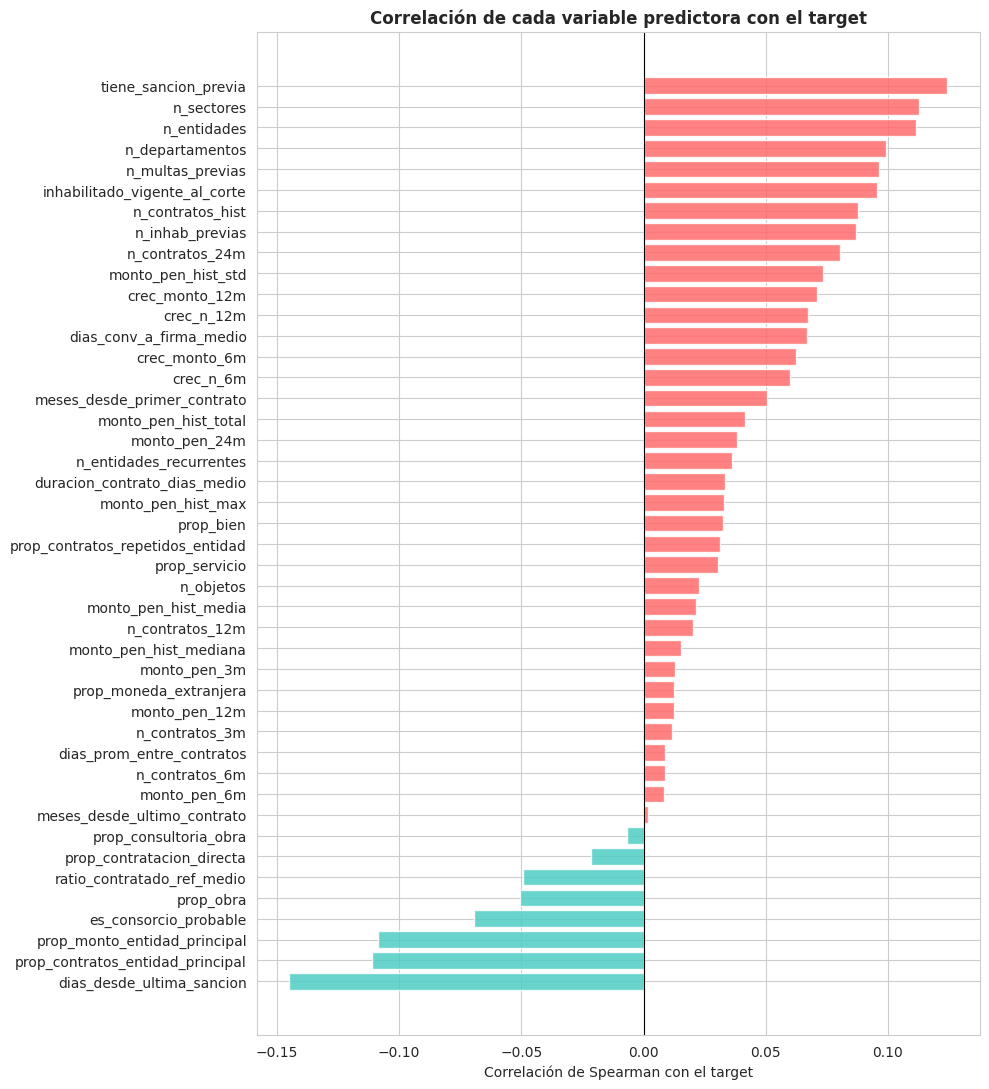

,Pearson,Spearman
dias_desde_ultima_sancion,-0.142,-0.145
tiene_sancion_previa,0.124,0.124
n_sectores,0.102,0.113
n_entidades,0.081,0.112
prop_contratos_entidad_principal,-0.111,-0.111
prop_monto_entidad_principal,-0.098,-0.109
n_departamentos,0.082,0.099
n_multas_previas,0.087,0.096
inhabilitado_vigente_al_corte,0.095,0.095
n_contratos_hist,0.074,0.088


In [18]:
corr_target = pd.DataFrame({
    "Pearson": df[PREDICTORAS].corrwith(df["target"]),
    "Spearman": df[PREDICTORAS].corrwith(df["target"], method="spearman"),
})
corr_target = corr_target.sort_values("Spearman")

fig, ax = plt.subplots(figsize=(10, 11))
colores = [COLOR_1 if v > 0 else COLOR_0 for v in corr_target["Spearman"]]
ax.barh(corr_target.index, corr_target["Spearman"], color=colores, alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlación de Spearman con el target")
ax.set_title("Correlación de cada variable predictora con el target", fontweight="bold")
plt.tight_layout()
plt.show()

display(corr_target.reindex(corr_target["Spearman"].abs().sort_values(ascending=False).index).head(12).round(3))

**Qué observamos.** Todas las correlaciones son **débiles**: ninguna supera 0,15 en valor absoluto. Las más altas son las de diversificación (`n_sectores`, `n_entidades`, `n_departamentos`), antecedentes (`tiene_sancion_previa`, `n_inhab_previas`, `n_multas_previas`) y actividad (`n_contratos_hist`, `n_contratos_24m`). La concentración en la entidad principal tiene correlación negativa (alrededor de -0,11), en parte porque los proveedores con un solo contrato concentran el 100 % por definición. Algunas variables, como las de monto, casi no tienen relación lineal ni monótona con el target.

`dias_desde_ultima_sancion` muestra una correlación negativa (a menos días desde la última sanción, mayor riesgo), pero se calcula con apenas 1 425 filas, por lo que debe tomarse con cautela.

**Por qué importa.** Ninguna variable por sí sola separa bien las clases; no esperamos un desempeño alto. Esto hace valioso comparar un baseline lineal (regresión logística) con modelos no lineales (árbol, KNN, MLP), y nos obliga a evaluar con métricas adecuadas al desbalance.

### 10.4 Correlación entre variables predictoras

Revisamos la colinealidad: variables muy correlacionadas entre sí aportan información repetida y dificultan interpretar los coeficientes de una regresión logística.

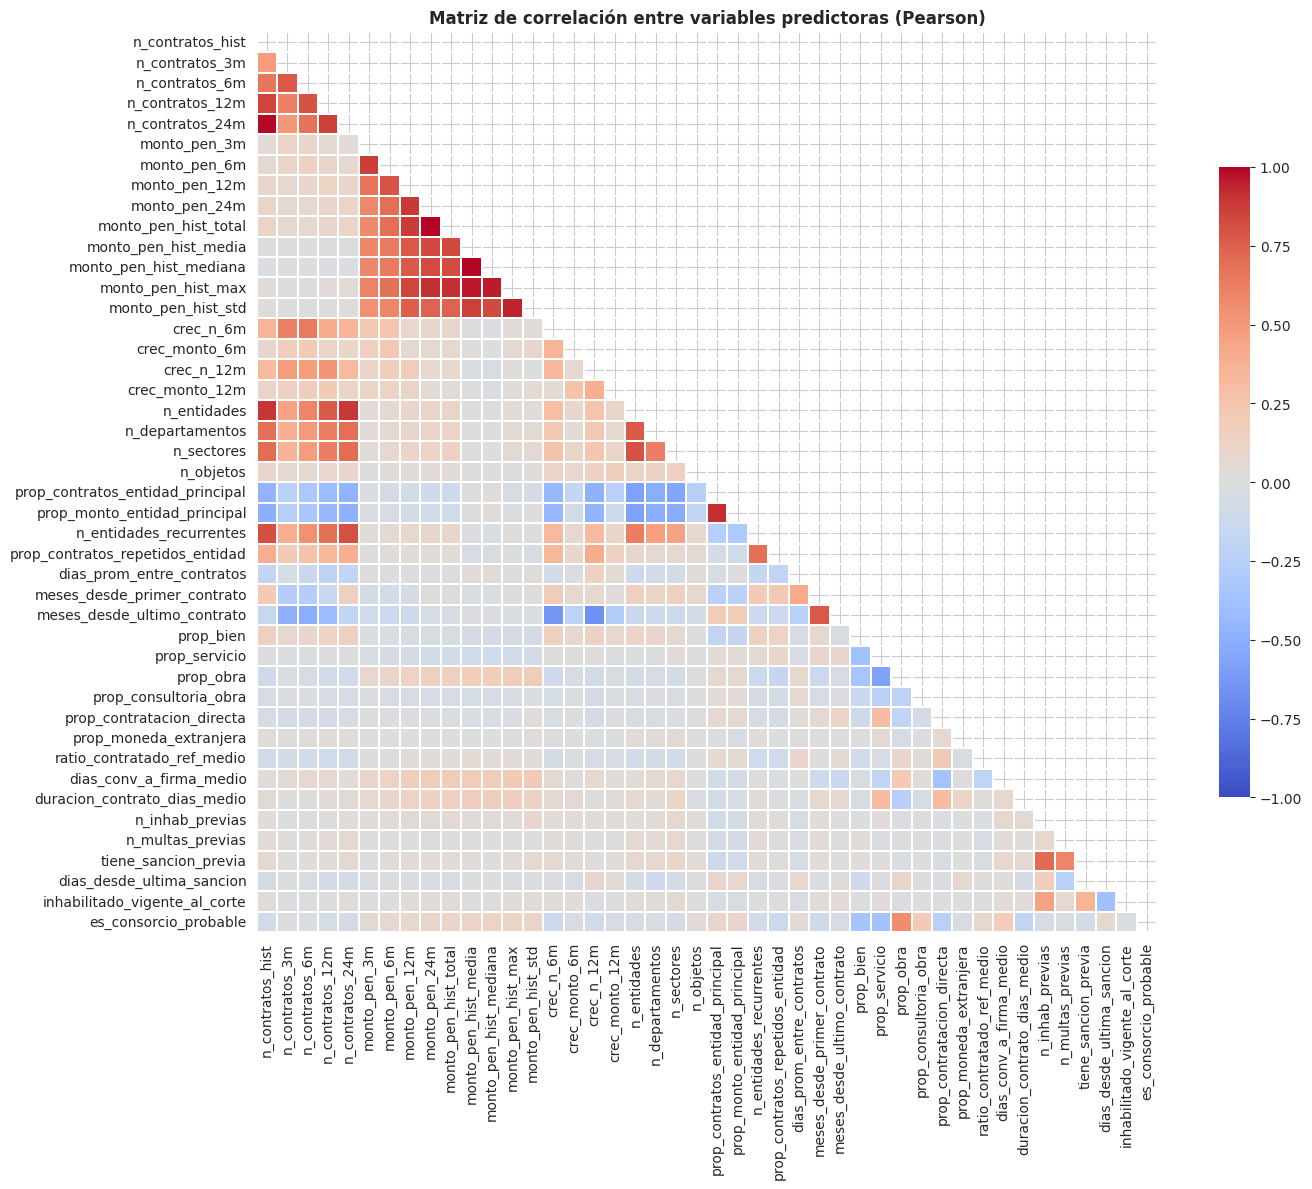

,variable_1,variable_2,correlación
0,monto_pen_hist_total,monto_pen_24m,0.998
1,monto_pen_hist_mediana,monto_pen_hist_media,0.998
2,n_contratos_24m,n_contratos_hist,0.990
3,monto_pen_hist_max,monto_pen_hist_media,0.967
4,monto_pen_hist_max,monto_pen_hist_mediana,0.959
5,monto_pen_hist_std,monto_pen_hist_max,0.938
6,monto_pen_hist_max,monto_pen_24m,0.918
7,monto_pen_hist_max,monto_pen_hist_total,0.916
8,prop_monto_entidad_principal,prop_contratos_entidad_principal,0.908


In [19]:
corr = df[PREDICTORAS].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mascara, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Matriz de correlación entre variables predictoras (Pearson)", fontweight="bold")
plt.tight_layout()
plt.show()

pares = corr.where(~mascara).stack()
pares_altos = pares[pares.abs() >= 0.9].sort_values(ascending=False)
pares_altos = pares_altos.rename("correlación").rename_axis(["variable_1", "variable_2"]).reset_index()
display(pares_altos.round(3))

**Qué observamos.** Hay **grupos de variables casi redundantes**:

- Los **montos**: `monto_pen_hist_media` y `monto_pen_hist_mediana` (0,998), `monto_pen_24m` y `monto_pen_hist_total` (0,998), y varios con `monto_pen_hist_max` (0,92 a 0,97).
- Los **conteos de contratos**: `n_contratos_hist` y `n_contratos_24m` (0,99), porque con una cobertura de entre 1 y 2,5 años la ventana de 24 meses casi coincide con todo el historial.
- La **concentración** por contratos y por monto (0,91).

**Decisión.** Para la regresión logística, que es sensible a la colinealidad, usaremos un subconjunto de variables sin pares casi duplicados (o regularización). Los árboles toleran la redundancia; para KNN conviene tener en cuenta que las variables repetidas pesan más en la distancia.

## 11. Evolución entre cortes

Comparamos cómo cambia el perfil de los datos de un corte a otro. Esto nos dice si los cortes son comparables, algo esencial para una partición temporal.

,filas,prevalencia,consorcios,con_sancion_previa,mediana_monto_12m,contratos_hist_medio
fecha_corte,,,,,,
2023-12-31,4144,2.32,39.62,3.98,467528.22,1.38
2024-06-30,6148,1.82,42.50,5.03,406095.78,1.51
2024-12-31,8406,2.47,46.05,5.02,160742.79,1.59
2025-06-30,10033,3.50,47.97,5.27,65808.60,1.67


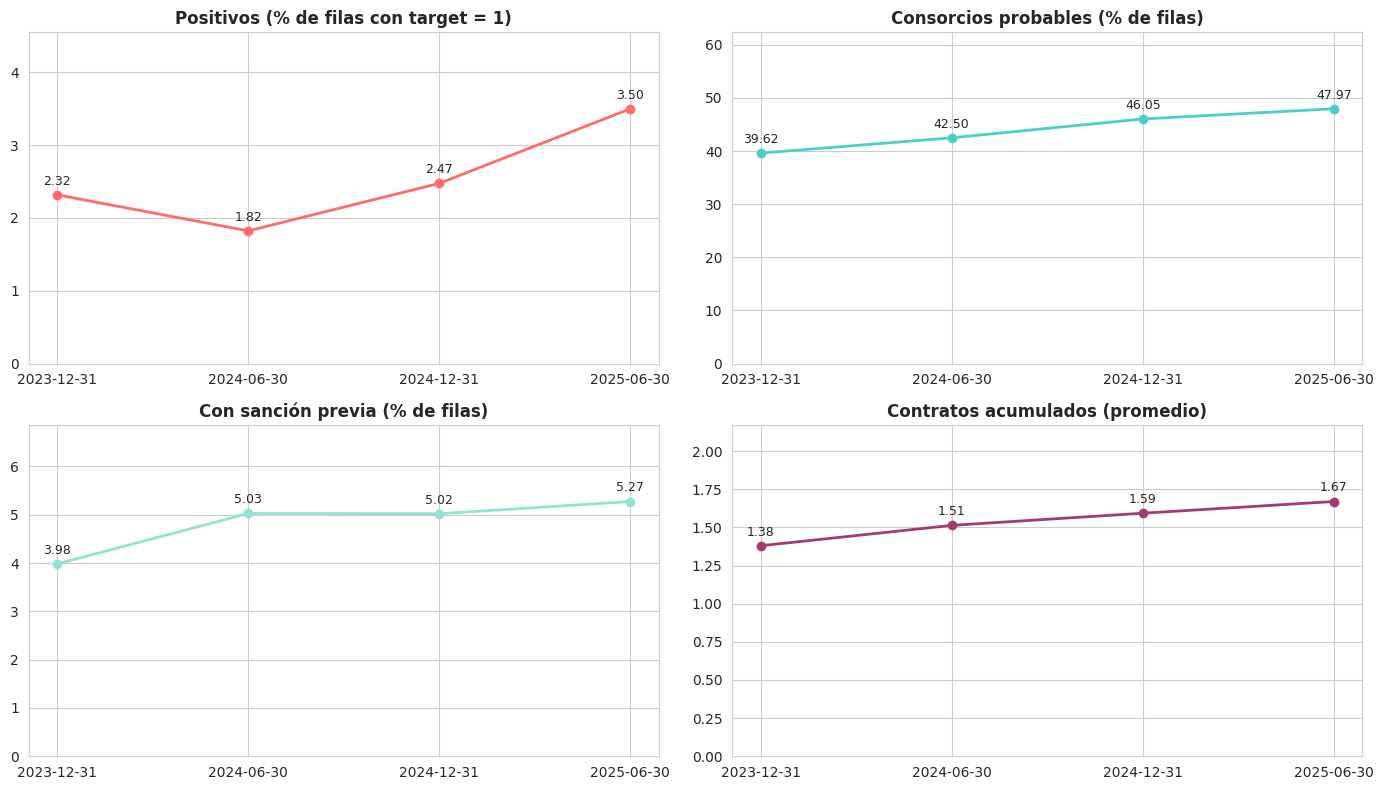

In [20]:
evolucion = df.groupby("fecha_corte").agg(
    filas=("target", "size"),
    prevalencia=("target", lambda s: s.mean() * 100),
    consorcios=("es_consorcio_probable", lambda s: s.mean() * 100),
    con_sancion_previa=("tiene_sancion_previa", lambda s: s.mean() * 100),
    mediana_monto_12m=("monto_pen_12m", "median"),
    contratos_hist_medio=("n_contratos_hist", "mean"),
)
display(evolucion.round(2))

etiquetas = evolucion.index.strftime("%Y-%m-%d")
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
series = [
    ("prevalencia", "Positivos (% de filas con target = 1)", COLOR_1),
    ("consorcios", "Consorcios probables (% de filas)", COLOR_0),
    ("con_sancion_previa", "Con sanción previa (% de filas)", "#95E1D3"),
    ("contratos_hist_medio", "Contratos acumulados (promedio)", "#A23B72"),
]
for ax, (col, titulo, color) in zip(axes.flatten(), series):
    ax.plot(etiquetas, evolucion[col], marker="o", color=color, linewidth=2)
    ax.set_title(titulo, fontweight="bold")
    ax.set_ylim(0, evolucion[col].max() * 1.3)
    for x, v in zip(etiquetas, evolucion[col]):
        ax.text(x, v + evolucion[col].max() * 0.04, f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Qué observamos**

- La prevalencia **no es constante**: 2,32 %, 1,82 %, 2,47 % y 3,50 %. El último corte tiene casi el doble de positivos relativos que el segundo. Con estos datos no podemos saber si refleja un aumento real del riesgo, un cambio en la forma o el momento de publicar sanciones, o simplemente más proveedores con historial.
- La proporción de **consorcios probables** crece de 39,6 % a 48,0 %, y la de proveedores con **sanción previa** de 4,0 % a 5,3 %: la composición de los cortes cambia con el tiempo.
- El número de contratos acumulados promedio también crece (de 1,38 a 1,67), porque el historial se acumula.
- La mediana del monto de los últimos 12 meses cae de unos 468 mil a unos 66 mil soles. No es que los contratos sean menores: la proporción de proveedores **sin contratos en los últimos 12 meses** sube de 0 % a 14 %, 36 % y 47 % entre el primer y el último corte (el historial acumula proveedores que dejaron de contratar), y entre los que sí tienen actividad la mediana se mantiene entre 470 mil y 610 mil soles.

**Por qué importa.** Los cortes **no son idénticamente distribuidos**: entrenar con cortes antiguos y evaluar en uno reciente implica enfrentar un cambio en la prevalencia y en la composición. Es una prueba realista, pero hay que tenerlo presente al interpretar las métricas, y por eso las comparaciones por prevalencia (PR-AUC frente a la tasa base de cada corte) son más justas que valores absolutos.

## 12. Conclusiones y decisiones para el modelado

### 12.1 Hallazgos principales

1. **Desbalance severo.** 767 positivos de 28 731 filas (2,67 %), unos 36 negativos por cada positivo, que corresponden a 487 proveedores distintos.
2. **Filas no independientes.** 10 033 proveedores producen 28 731 filas; el historial es acumulativo y los mismos proveedores se repiten entre cortes.
3. **Nulos estructurales.** 12 de las 44 predictoras tienen nulos con significado propio. Casi todas las filas (99,7 %) tienen al menos uno, así que eliminar filas no es viable.
4. **Escalas muy distintas y colas largas.** Los montos, conteos y días tienen sesgo fuerte a la derecha y rangos que difieren en varios órdenes de magnitud.
5. **Los valores extremos concentran positivos.** Eliminarlos sacrificaría señal.
6. **Señal débil pero presente.** Las mejores variables son los antecedentes de sanción, la diversificación (entidades, sectores, departamentos) y el número de contratos. Ninguna correlación supera 0,15.
7. **Redundancia entre variables.** Montos y conteos por ventana están casi duplicados.
8. **Cortes con prevalencia y composición cambiantes.**

### 12.2 Decisiones

| Aspecto | Decisión para `02_modelos.ipynb` |
|---|---|
| Variables excluidas | `id_proveedor`, `fecha_corte`, `fecha_fin_ventana`, `ventana_etiqueta_completa`, `etiqueta_confiable`, `meses_cobertura_datos` (identifican el corte o son constantes) y `y_inhabilitacion_12m` / `y_multa_12m` (componentes del target). Quedan las 44 predictoras. |
| Partición | **Temporal por fecha de corte**, no aleatoria, para evitar que un mismo proveedor quede en entrenamiento y prueba. |
| Métricas | PR-AUC (principal), recall, precision, F1 y ROC-AUC; comparar contra la prevalencia como referencia mínima. No usar accuracy. |
| Desbalance | Pesos de clase y ajuste de umbral; evaluar SMOTE solo sobre entrenamiento. |
| Valores faltantes | Sin eliminar filas. Imputar con estadísticos de entrenamiento (media, mediana, KNN) y comparar; evaluar indicadores de dato no disponible. |
| Escalas | `StandardScaler` y `MinMaxScaler` ajustados con entrenamiento para KNN, regresión logística y MLP; no necesario para el árbol. |
| Valores atípicos | No eliminar. Evaluar *clipping* por IQR con límites de entrenamiento para los modelos sensibles a escala. |
| Colinealidad | Para regresión logística, quitar variables redundantes o regularizar. |

### 12.3 Consideración sobre la partición temporal

La etiqueta de un corte solo se conoce al terminar su ventana de 12 meses. Por eso, al predecir en un corte, solo pueden usarse para entrenar los cortes cuya ventana ya había terminado en esa fecha:

| Corte | Fin de la ventana de la etiqueta |
|---|---|
| 2023-12-31 | 2024-12-31 |
| 2024-06-30 | 2025-06-30 |
| 2024-12-31 | 2025-12-31 |
| 2025-06-30 | 2026-06-30 |

Por ejemplo, para evaluar en el corte de 2025-06-30, un entrenamiento sin fuga de información solo podría usar los cortes de 2023-12-31 y 2024-06-30. Además, las ventanas de cortes semestrales se solapan seis meses, así que dos cortes consecutivos comparten parte de su periodo de etiqueta. La configuración final de entrenamiento, validación y prueba se definirá en `02_modelos.ipynb` respetando esta restricción.

### 12.4 Limitaciones

- **Etiqueta incompleta por construcción.** "Sin sanción" significa que no la observamos en las bases oficiales durante la ventana; no implica buen comportamiento. Además, las listas de sanciones solo conservan las vigentes o terminadas en los últimos años, por lo que los antecedentes lejanos pueden faltar.
- **Cobertura corta.** Los contratos disponibles empiezan en 2023. Las ventanas de 24 meses y las variables de crecimiento quedan truncadas o nulas en los primeros cortes.
- **Pocos positivos.** 767 filas (487 proveedores) limitan la estabilidad de los modelos, sobre todo al dividir por corte.
- **Montos solo en soles.** Los contratos en otra moneda cuentan como actividad pero no como monto.
- **Posible subregistro en consorcios.** Su etiqueta se busca con el RUC de pago, por lo que algunas sanciones podrían no observarse.
- **Calidad de campos.** Algunas fechas y montos tienen inconsistencias (firma anterior a la convocatoria, montos superiores al referencial) que no corregimos.
- **Uso responsable.** Los resultados sirven para priorizar revisiones y no deben interpretarse como evidencia de culpabilidad, fraude o corrupción.